In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn.functional as F

This notebook highlights the importance of gradients and activations and their statistics. 

In [11]:
# read in words 
words = open("data/names.txt", "r").read().splitlines()

In [12]:
# Construct mappings between characters and indicies
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)} # string-to-index
stoi["."] = 0
itos = {i:s for s, i in stoi.items()} # index-to-string

In [13]:
# Build the dataset, with splitting of input sets
blocksize = 3

# Set the context length 
def build_dataset(words, blocksize=blocksize):
    blocksize = blocksize
    X, Y = [], []

    for w in words:
        context = [0] * blocksize
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "--->", itos[ix])
            context = context[1:] + [ix] 

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

# shuffle up the input data, and split up the data
import random
random.seed(67)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1], blocksize=blocksize)
Xdev, Ydev = build_dataset(words[n1:n2], blocksize=blocksize)
Xtest, Ytest = build_dataset(words[n2:], blocksize=blocksize)

In [14]:
# Expected loss for all letters equally likely
-torch.tensor(1/27).log()

tensor(3.2958)

### Initialization
It's important to initialize with reasonable guesses. Starting the NN parameters with random numbers can result in very bad guesses, leading to a very high loss. The initial loss will be capped near a lower value ($-\log(1/27)=3.3$) if the outputs are initialized with near zeros.

Note that biases can be set to exactly zero, but weights should not be exactly zero. Output weights should be near zero, so that the gradient will still impact parameter updates. 

Importantly, deeper networks become more sensitive to bad initializations, so its importent to be careful and to consider the ways training can run afoul. 

In [15]:
n_embed = 10
n_hidden = 200
batch_size = 32

# Initialize the NN params
g = torch.Generator().manual_seed(67)
C = torch.randn((batch_size, n_embed), generator=g) # 10 D n_embed
# Scale by the kaiming init for tanh nonlinearity
W1 = torch.randn((n_embed * blocksize, n_hidden), generator=g) * (5/3) / (n_embed * blocksize)**0.5
# b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, batch_size), generator=g) * 0.01
b2 = torch.randn(batch_size, generator=g) * 0

# Parameters, etc. related to batch normalization
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
for p in parameters:
    p.requires_grad = True

But, how are these constants for minimizing initial weights set? 

tensor(0.0030) tensor(1.0032)
tensor(-0.0107) tensor(3.2294)


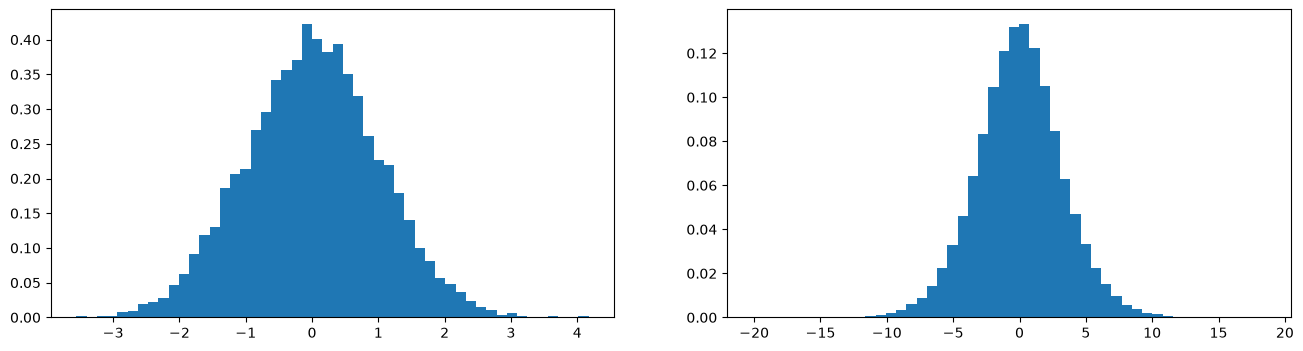

In [16]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) #/ 10**0.5
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(16,4))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);

Notice the large increase in the standard deviation after activation. This is undesirable. So the idea is to scale w, so that the standard deviation is roughly similar after activation. The heuristic is, divide the matrix by the square root of the number of inputs. So in this case above, $$y = x @ (w / \sqrt{10})$$

In fact, torch has a commonly used function for initializing weights in this way : `torch.nn.init.kaiming_normal_()` (Kaiming He et al. authored the paper which analyzes the weight initializations forward and back propogation behavior )

### Batch normalization
More important than proper initialization is batch normalization (2015).  
Preactivation inputs to $\tanh()$ need to be roughly a normalized gaussian, 0 mean and std 1. So just normalize them to be gaussian. 
We normalize the batches before passing them into the activation function, so they are unit gaussian during intialization. Then, a gain and bias is applied to the gaussian to allow training to shift and squeeze and otherwise alter the input pre-activation gaussian. 

The "problem" with batch normalization is that the examples in the batches are coupled to one another; they are no longer computed independently. This creates variability in the preactivation value and in $h$. This variability is actually helpful for training because it results in an added stochastic effect which reduces overfitting.

Additionally, the bias `b1` does nothing in batch normalization, so may as well remove it. The batch normalization bias `bnbias` takes care of the bias addition. 

During normalization, it can also be a good idea to add a small number $\epsilon$ in the denominator to ensure values are well behaved and there is no division by zero.

**NB**: Batch Normalization can be highly error prone due to coupling of examples in forward passes. So, in practice, other kinds of normalization layers like group normalization or layer normalization are used more commonly.

In [18]:
# Train the NN
runs = 200000
loses = []
stepi = []

In [19]:
for k in range(runs):

    # Construct minibatch
    batch = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[batch], Ytr[batch]

    # Forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    # Linear layer
    hpreact = embcat @ W1 # + b1
    # BatchNorm layer
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True) 
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # Nonlinear activation
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Yb)

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    lr = 0.1 if k < 100000 else 0.1
    for p in parameters:
        p.data += -lr * p.grad 

    # Track stats
    if k % 10000 == 0:
        print(f"step { k } :    | loss : { loss }")

    loses.append(loss.item())
    stepi.append(k)

    # break

print(loses[-1])

step 0 :    | loss : 3.464580774307251
step 10000 :    | loss : 2.0410032272338867
step 20000 :    | loss : 2.228632926940918
step 30000 :    | loss : 2.2764976024627686
step 40000 :    | loss : 2.3863773345947266
step 50000 :    | loss : 1.962496042251587
step 60000 :    | loss : 2.1706442832946777
step 70000 :    | loss : 2.822204828262329
step 80000 :    | loss : 1.9993517398834229
step 90000 :    | loss : 2.124176025390625
step 100000 :    | loss : 2.3915064334869385
step 110000 :    | loss : 2.4758126735687256
step 120000 :    | loss : 2.3429510593414307
step 130000 :    | loss : 1.9926435947418213
step 140000 :    | loss : 1.8178881406784058
step 150000 :    | loss : 2.2126336097717285
step 160000 :    | loss : 2.1038124561309814
step 170000 :    | loss : 1.773262858390808
step 180000 :    | loss : 1.9513317346572876
step 190000 :    | loss : 2.0474741458892822
2.576850175857544


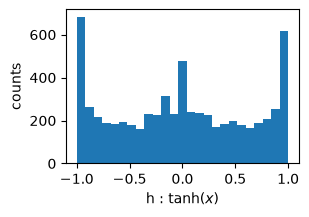

In [23]:
# What happens with h?
fig, ax = plt.subplots(figsize=(3,2))
ax.hist(h.view(-1).tolist(), 25)
ax.set_xlabel(r"h : $\tanh(x)$")
ax.set_ylabel("counts")
# fig.savefig("figures/tanh_before_smart_initialization.png")
fig.savefig("figures/tanh_after_smart_initialization.png")

Almost all the $h$ values are essentially 1, or -1. This is big problem because on back propagation, it becomes very difficult to change parameter. The gradient update is `self.grad += (1 - h**2) * out.grad`, which kills changes to the gradient change, since we multiply by nearly zero.

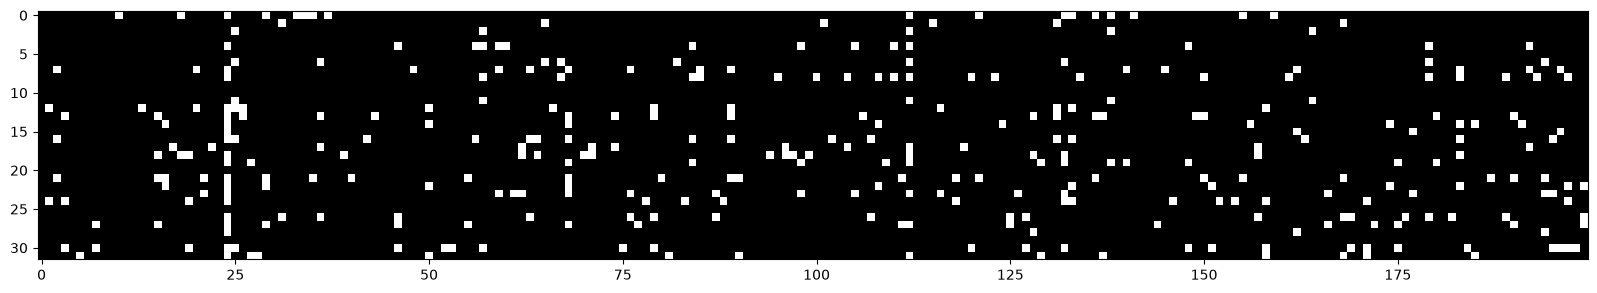

In [24]:
# Check for dead neurons
plt.figure(figsize=(20,5))
plt.imshow(h[:32].abs() > 0.99, cmap="gray", interpolation="nearest")
fig.savefig("figures/batch_tanh_after_smart_initialization.png")

Some neurons are nearly dead, but there aren't any totally white columns. The problem is that the pre-activation values (before $\tanh$) are just too large. 

At the end of training, we need to calibrate the batch norm. This allows us to use the trained network to make individual predictions, although it was trained on batches.
This does not need to be computed after the fact; it can be comptuted during training, which has been incorporated above.

In [25]:
# Pass the full training set through
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 #+ b1
    # Comput the mean / std over the full training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

In [26]:
# Just use the BN mean / std that were computed at runtime
bnmean = bnmean_running
bnstd = bnstd_running

In [27]:
# Evaluate loss
def split_loss(split):
    x,y = {
        "train" : (Xtr, Ytr),
        "val" : (Xdev, Ydev),
        "test" : (Xtest, Ytest)
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1) 
    hpreact = embcat @ W1 # + b1
    hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    return loss

print(f"Training loss : { split_loss("train") }")
print(f"Validation loss : { split_loss("val") }")

Training loss : 2.1243112087249756
Validation loss : 2.150055170059204


In [28]:
# Sample form the model
g = torch.Generator().manual_seed(67)

for _ in range(25):
    out = []
    context = [0] * blocksize
    while True:
        emb = C[torch.tensor([context])]
        embcat = emb.view(emb.shape[0], -1) 

        hpreact = embcat @ W1 #+ b1
        hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
        h = torch.tanh(hpreact)

        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

jobethriel.
cren.
ralain.
jamaya.
kendrier.
kanaislyn.
myana.
bian.
cathn.
hire.
jianna.
urailey.
khoysleenaharleya.
akaziya.
aria.
cope.
ana.
yubiahsimika.
aveya.
deardaemespitra.
avianny.
hason.
cayne.
kio.
darrosielle.


In [54]:
# The classes here are the same API as nn.Module in PyTorch

class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    # gaussian initialization + kaiming weighting
    self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      xmean = x.mean(0, keepdim=True) # batch mean
      xvar = x.var(0, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(67) # for reproducibility
vocab_size = 27
block_size = 3

C = torch.randn((vocab_size, n_embd),            generator=g)
layers = [
  Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
  Linear(           n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size),
]

with torch.no_grad():
  # last layer: make less confident
  layers[-1].gamma *= 0.1
  #layers[-1].weight *= 0.1
  # all other layers: apply gain
  for layer in layers[:-1]:
    if isinstance(layer, Linear):
      layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.requires_grad = True

47024


In [55]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  emb = C[Xb] # embed the characters into vectors
  x = emb.view(emb.shape[0], -1) # concatenate the vectors
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb) # loss function
  
  # backward pass
  for layer in layers:
    layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
  with torch.no_grad():
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

  # if i >= 1000:
  #   break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.2774
  10000/ 200000: 3.0069
  20000/ 200000: 1.9010
  30000/ 200000: 2.5519
  40000/ 200000: 2.3122
  50000/ 200000: 2.1109
  60000/ 200000: 1.9770
  70000/ 200000: 2.2508
  80000/ 200000: 2.1134
  90000/ 200000: 2.4361
 100000/ 200000: 2.0337
 110000/ 200000: 1.9854
 120000/ 200000: 2.4188
 130000/ 200000: 1.9619
 140000/ 200000: 1.9901
 150000/ 200000: 2.0471
 160000/ 200000: 1.9275
 170000/ 200000: 2.3868
 180000/ 200000: 1.7795
 190000/ 200000: 1.8413


### Check statistics
Check the statistics of the forward pass and the backward pass (especially if there are no batch normalization layers)

For the `tanh` layers, look at the outputs. The mean is zero and the standard deviation is 0.66 -> this implies consistent scaling as we pass through successive layers.  
These layers are squashing functions, so the distribution gets compressed on successive passes. That is why the gain is needed, keeping the output distributions consistent ($5/3$ for $\tanh(x)$).

layer 2 (      Tanh): mean +0.02, std 0.70, saturated: 16.59%
layer 5 (      Tanh): mean +0.02, std 0.74, saturated: 19.31%
layer 8 (      Tanh): mean +0.03, std 0.76, saturated: 17.81%
layer 11 (      Tanh): mean +0.02, std 0.78, saturated: 20.69%
layer 14 (      Tanh): mean -0.03, std 0.81, saturated: 23.41%


Text(0.5, 1.0, 'activation distribution')

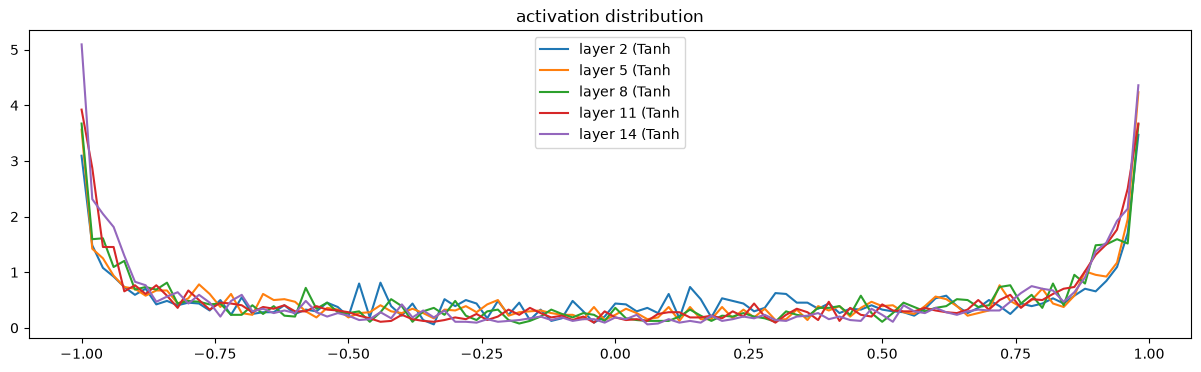

In [56]:
# visualize histograms
plt.figure(figsize=(15, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

Check: All the different have roughly the same gradient. Again, this depends on the setting of the gain.

layer 2 (      Tanh): mean -0.000000, std 4.168121e-03
layer 5 (      Tanh): mean +0.000000, std 3.700076e-03
layer 8 (      Tanh): mean -0.000000, std 3.566085e-03
layer 11 (      Tanh): mean +0.000000, std 3.348448e-03
layer 14 (      Tanh): mean -0.000000, std 3.687278e-03


Text(0.5, 1.0, 'gradient distribution')

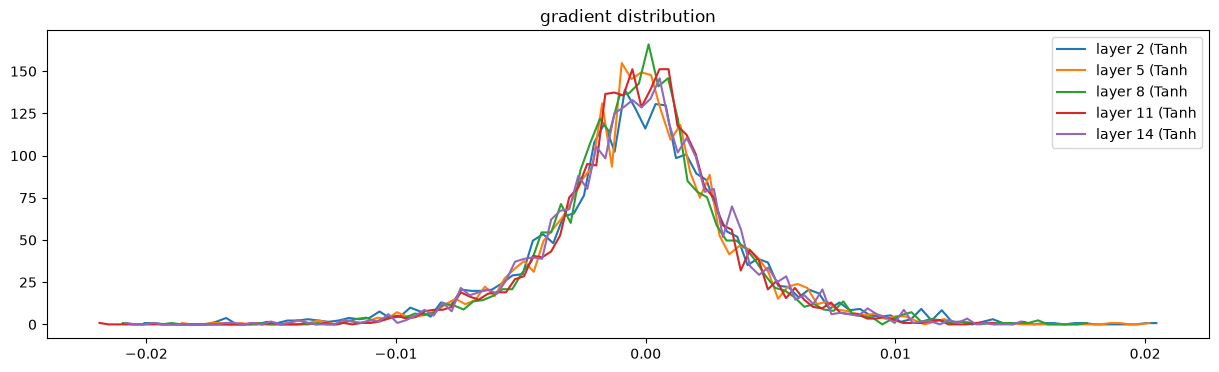

In [57]:
# visualize histograms of gradients
plt.figure(figsize=(15, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

Check: the weights of the linear parameters. Their relevant statistics include the mean and the standard deviation, but also the ration of the gradients to the values. It is important to compare the scale of the gradient to the scale of the values, because the this effects the size of the step update. Notice the final layer is learning faster than the other layers.

weight   (27, 10) | mean -0.000000 | std 1.271605e-02 | grad:data ratio 1.097669e-02
weight  (30, 100) | mean -0.000145 | std 7.506812e-03 | grad:data ratio 1.687120e-02
weight (100, 100) | mean +0.000029 | std 4.831520e-03 | grad:data ratio 1.776306e-02
weight (100, 100) | mean +0.000085 | std 5.124519e-03 | grad:data ratio 1.902244e-02
weight (100, 100) | mean +0.000046 | std 4.633555e-03 | grad:data ratio 1.773336e-02
weight (100, 100) | mean -0.000052 | std 4.686276e-03 | grad:data ratio 1.875759e-02
weight  (100, 27) | mean +0.000060 | std 7.097336e-03 | grad:data ratio 1.885178e-02


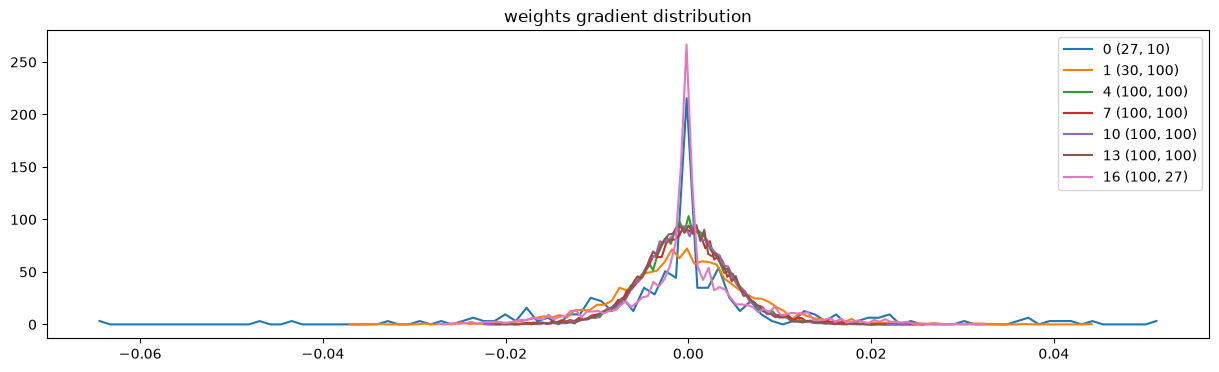

In [58]:
# visualize histograms
plt.figure(figsize=(15, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

Now, look at how the gradient to value ratios change over training, once the learning rate is accounted for. A good ratio is about $1/1000$, so in the $\log$ scaled plot below, $-3$. 
Note the last layer is less confident, so its ratio will be higher.
The sudden jump here is due to a change to the learning rate in the training loop.

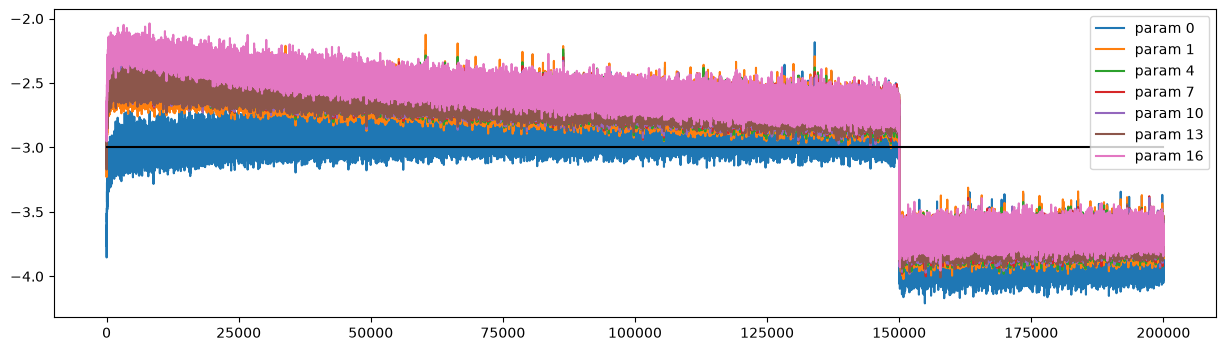

In [59]:
plt.figure(figsize=(15, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);


In [62]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xtest, Ytest),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

train 2.0054023265838623
val 2.0606465339660645


In [63]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

carlah.
amillie.
hawn.
shreet.
khalaysie.
rahnen.
deliah.
jareei.
nellara.
chaiir.
kaleigh.
ham.
joce.
quint.
shon.
walianni.
waterri.
jaryn.
kai.
evellsabee.
